# UAV Energy Prediction — Final EDA, Cleaning, Feature Selection and Split Notebook

## 1. Load Libraries and Dataset

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset path
DATA_PATH = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_ml_ready_10hz_expanded.csv")

# Project paths
PROJECT_DIR = DATA_PATH.parents[1]
EDA_DIR = PROJECT_DIR / "eda_outputs"
PROCESSED_DIR = PROJECT_DIR / "processed_10hz"
SPLIT_DIR = PROJECT_DIR / "splits"

for folder in [EDA_DIR, PROCESSED_DIR, SPLIT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Unique flights:", df["log_id"].nunique())

print("\nDataset label distribution:")
print(df["dataset_label"].value_counts())

display(df.head())

Dataset loaded successfully
Shape: (1019991, 378)
Unique flights: 172

Dataset label distribution:
dataset_label
normal      719371
abnormal    300620
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Basic Dataset Summary

In [3]:
dataset_summary = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total columns",
        "Unique flight logs",
        "Normal rows",
        "Abnormal rows",
        "Normal flight logs",
        "Abnormal flight logs",
        "Sampling rate",
        "Main target"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df["log_id"].nunique(),
        df[df["dataset_label"] == "normal"].shape[0],
        df[df["dataset_label"] == "abnormal"].shape[0],
        df[df["dataset_label"] == "normal"]["log_id"].nunique(),
        df[df["dataset_label"] == "abnormal"]["log_id"].nunique(),
        "10 Hz",
        "target_energy_next_60s_wh"
    ]
})

display(dataset_summary)

dataset_summary.to_csv(
    EDA_DIR / "01_final_dataset_summary.csv",
    index=False
)

,Metric,Value
0,Total rows,1019991
1,Total columns,378
2,Unique flight logs,172
3,Normal rows,719371
4,Abnormal rows,300620
5,Normal flight logs,129
6,Abnormal flight logs,43
7,Sampling rate,10 Hz
8,Main target,target_energy_next_60s_wh


## 3. Main battery and target columns

In [4]:
main_cols = [
    "log_id",
    "dataset_label",
    "time_td",
    "time_s",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "power_w",
    "energy_increment_wh",
    "cumulative_energy_wh",
    "future_cumulative_energy_wh",
    "target_energy_next_60s_wh"
]

main_col_report = pd.DataFrame({
    "column": main_cols,
    "exists": [col in df.columns for col in main_cols],
    "missing_count": [
        df[col].isna().sum() if col in df.columns else np.nan
        for col in main_cols
    ],
    "missing_percent": [
        df[col].isna().mean() * 100 if col in df.columns else np.nan
        for col in main_cols
    ]
})

display(main_col_report)

main_col_report.to_csv(
    EDA_DIR / "02_main_column_missing_report.csv",
    index=False
)

,column,exists,missing_count,missing_percent
0,log_id,True,0,0.0
1,dataset_label,True,0,0.0
2,time_td,True,0,0.0
3,time_s,True,0,0.0
4,battery_status__voltage_v,True,0,0.0
5,battery_status__voltage_filtered_v,True,0,0.0
6,battery_status__current_a,True,0,0.0
7,power_w,True,0,0.0
8,energy_increment_wh,True,0,0.0
9,cumulative_energy_wh,True,0,0.0


In [5]:
target_col = "target_energy_next_60s_wh"

# Columns not used as model input
non_feature_cols = [
    "log_id",          # used for flight-level splitting only
    "dataset_label",   # used for normal/abnormal analysis only
    "time_td"          # duplicate time format; time_s is used instead
]

# Future/target-derived columns that would cause leakage
leakage_cols = [
    "target_energy_next_60s_wh",
    "future_cumulative_energy_wh",
    "future_remaining_60s",
    "target_remaining_drop_60s"
]

cols_to_exclude = non_feature_cols + leakage_cols

allowed_core_features = [
    "time_s",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__current_average_a",
    "battery_status__remaining",
    "battery_status__discharged_mah",
    "power_w",
    "energy_increment_wh",
    "cumulative_energy_wh"
]

print("Target column:", target_col)
print("Target exists:", target_col in df.columns)

print("\nAllowed core features available:")
for col in allowed_core_features:
    print(col, ":", col in df.columns)

Target column: target_energy_next_60s_wh
Target exists: True

Allowed core features available:
time_s : True
battery_status__voltage_v : True
battery_status__voltage_filtered_v : True
battery_status__current_a : True
battery_status__current_filtered_a : True
battery_status__current_average_a : True
battery_status__remaining : True
battery_status__discharged_mah : True
power_w : True
energy_increment_wh : True
cumulative_energy_wh : True


## 4. Split by log_id before feature selection

In [6]:
from sklearn.model_selection import train_test_split

unique_flights = df[["log_id", "dataset_label"]].drop_duplicates()

train_flights, temp_flights = train_test_split(
    unique_flights,
    test_size=0.30,
    random_state=42,
    stratify=unique_flights["dataset_label"]
)

val_flights, test_flights = train_test_split(
    temp_flights,
    test_size=0.50,
    random_state=42,
    stratify=temp_flights["dataset_label"]
)

train_df = df[df["log_id"].isin(train_flights["log_id"])].copy()
val_df = df[df["log_id"].isin(val_flights["log_id"])].copy()
test_df = df[df["log_id"].isin(test_flights["log_id"])].copy()

print("Train rows:", train_df.shape)
print("Validation rows:", val_df.shape)
print("Test rows:", test_df.shape)

print("\nTrain flights:", train_df["log_id"].nunique())
print("Validation flights:", val_df["log_id"].nunique())
print("Test flights:", test_df["log_id"].nunique())

Train rows: (631004, 378)
Validation rows: (185751, 378)
Test rows: (203236, 378)

Train flights: 120
Validation flights: 26
Test flights: 26


## 5. Create missing-value report using training data

In [7]:
missing_report = pd.DataFrame({
    "column": train_df.columns,
    "missing_count_train": train_df.isna().sum().values,
    "missing_percent_train": train_df.isna().mean().values * 100,
    "data_type": train_df.dtypes.astype(str).values,
    "unique_values_train": train_df.nunique(dropna=True).values
})

missing_report = missing_report.sort_values(
    "missing_percent_train",
    ascending=False
).reset_index(drop=True)

display(missing_report.head(50))

,column,missing_count_train,missing_percent_train,data_type,unique_values_train
0,vehicle_status__pre_flight_checks_pass,631004,100.0,float64,0
1,vehicle_gps_position__selected_rtcm_instance,631004,100.0,float64,0
2,vehicle_air_data__time_td,631004,100.0,float64,0
3,vehicle_air_data__rho,631004,100.0,float64,0
4,vehicle_air_data__baro_pressure_pa,631004,100.0,float64,0
5,vehicle_air_data__baro_temp_celcius,631004,100.0,float64,0
6,vehicle_air_data__baro_alt_meter,631004,100.0,float64,0
7,vehicle_gps_position__spoofing_state,631004,100.0,float64,0
8,vehicle_gps_position__rtcm_crc_failed,631004,100.0,float64,0
9,vehicle_attitude__delta_q_reset[1],631004,100.0,float64,0


Columns with any missing values: 357 / 378


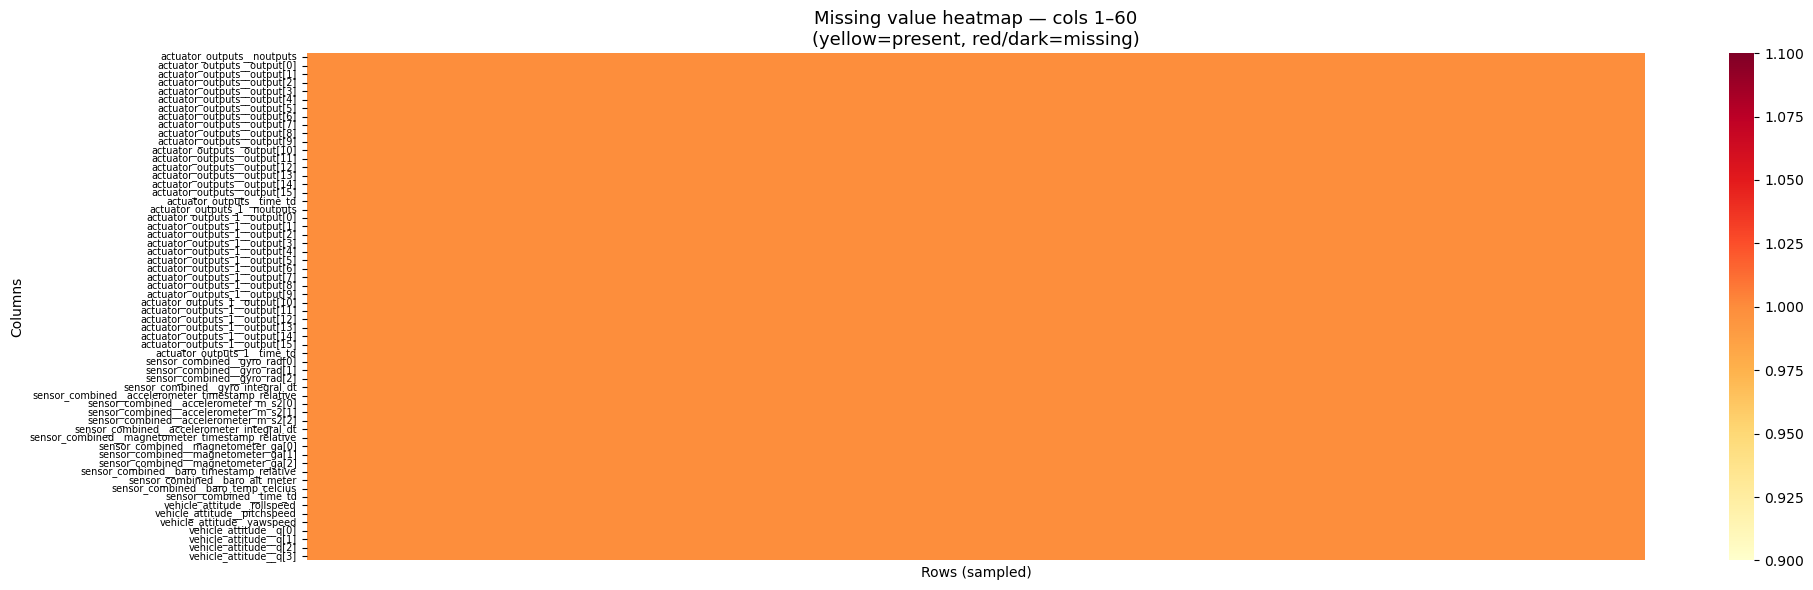

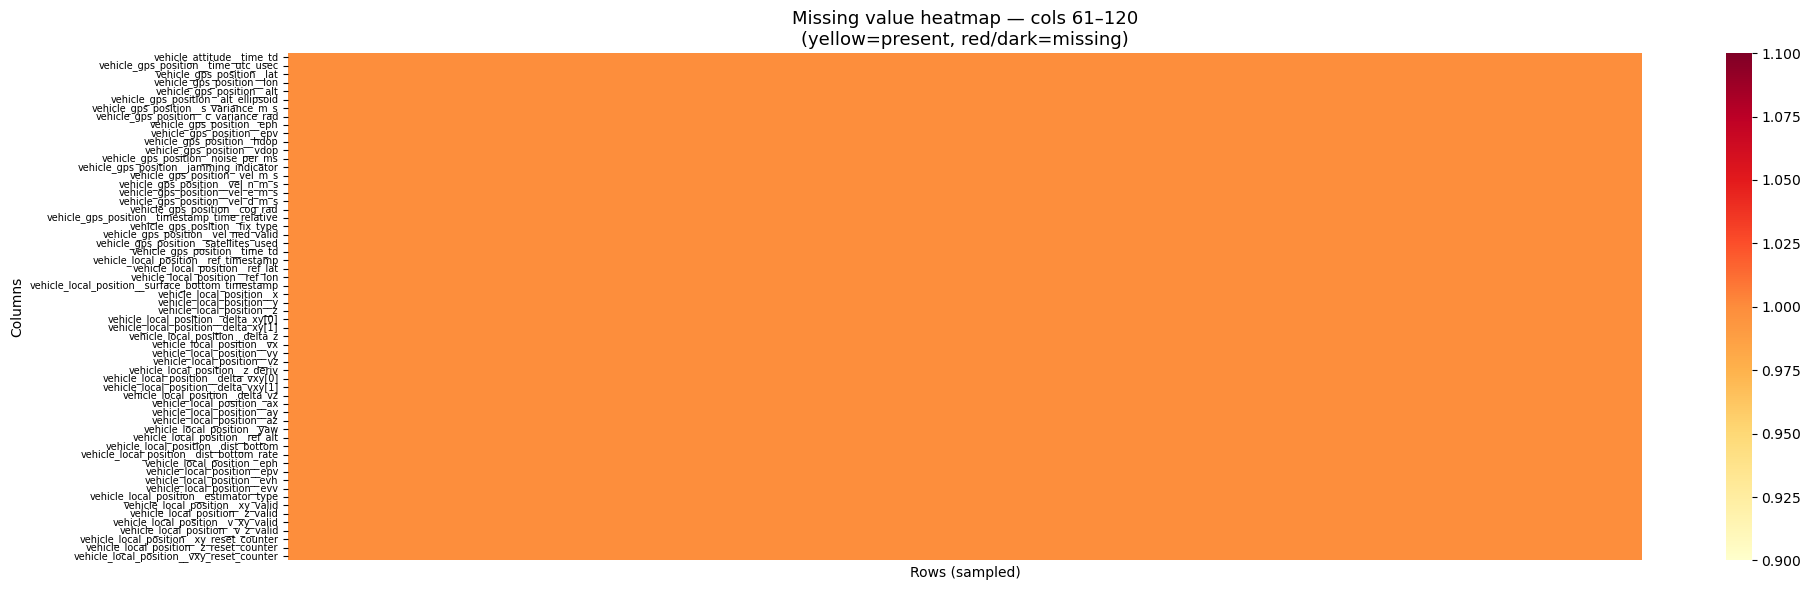

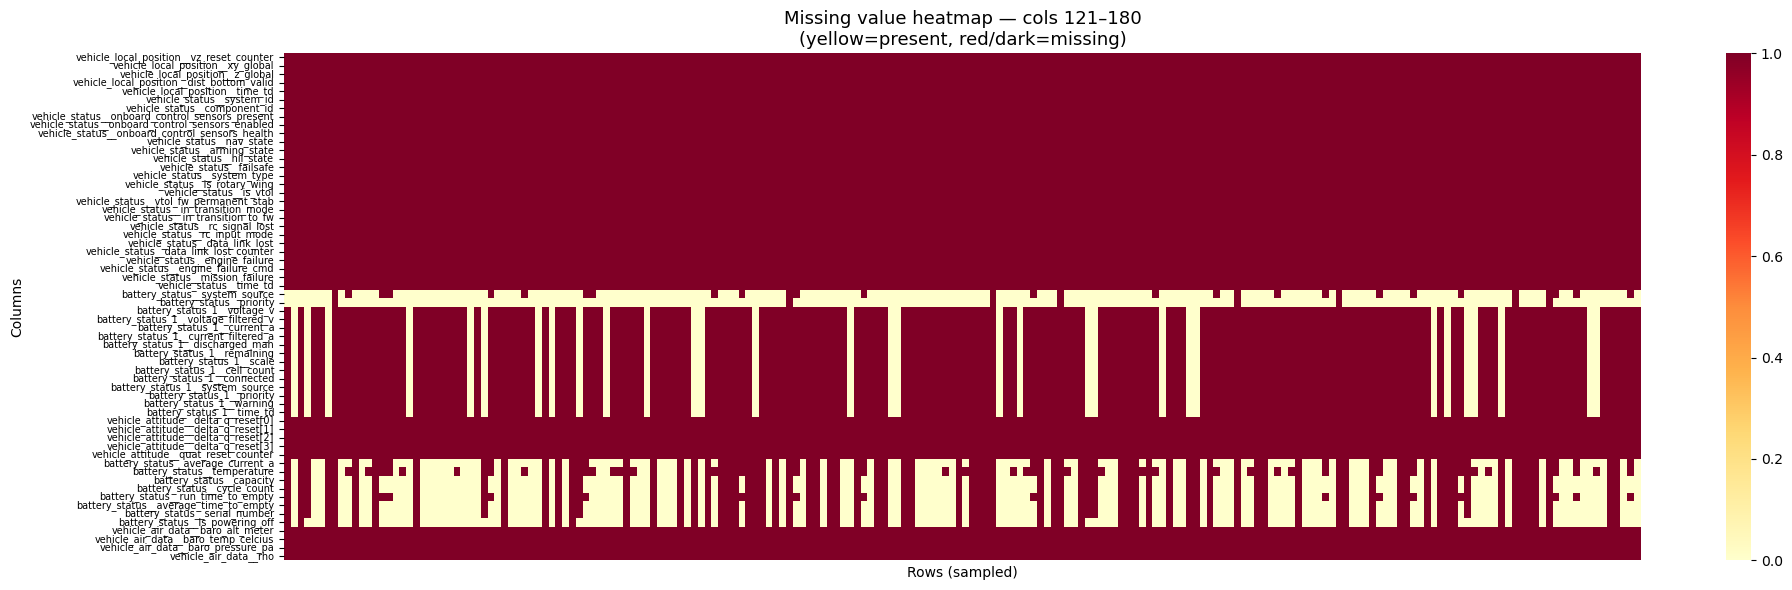

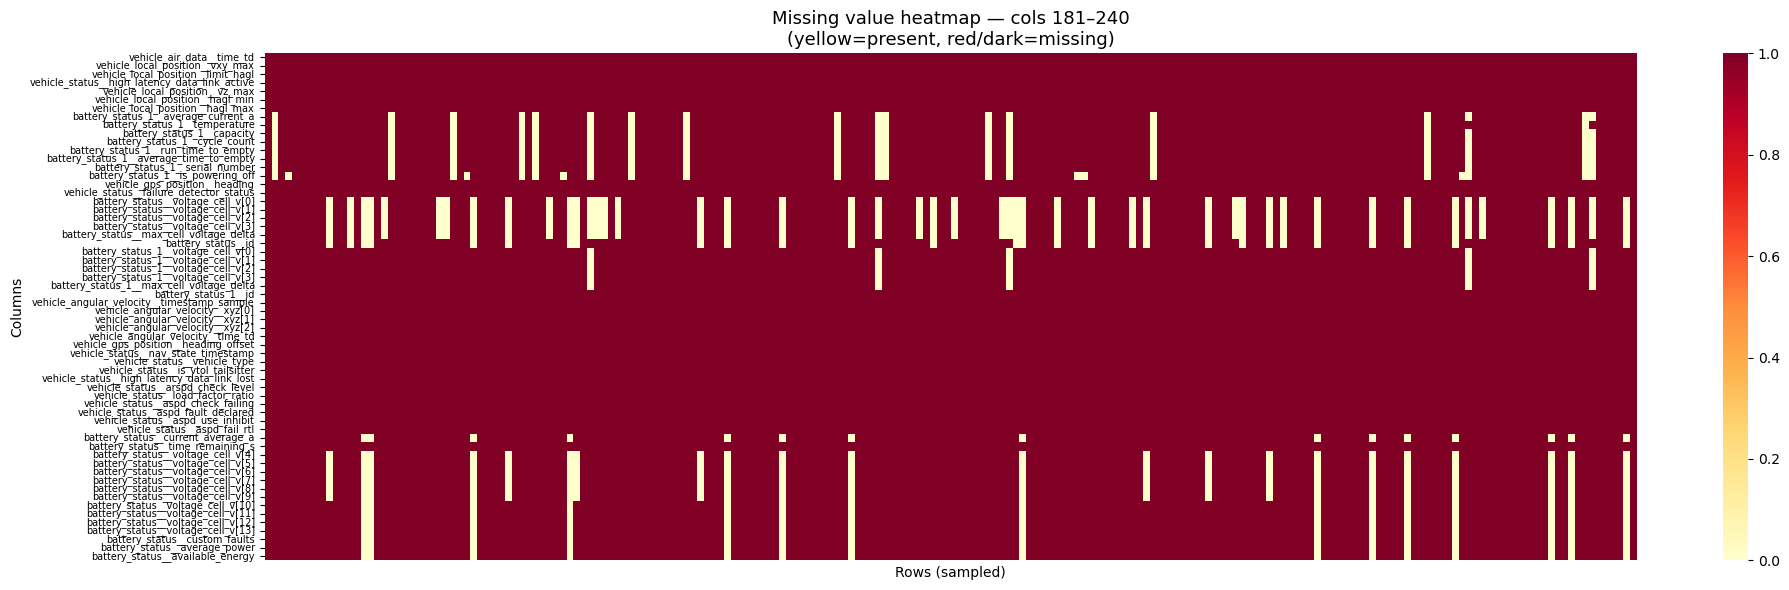

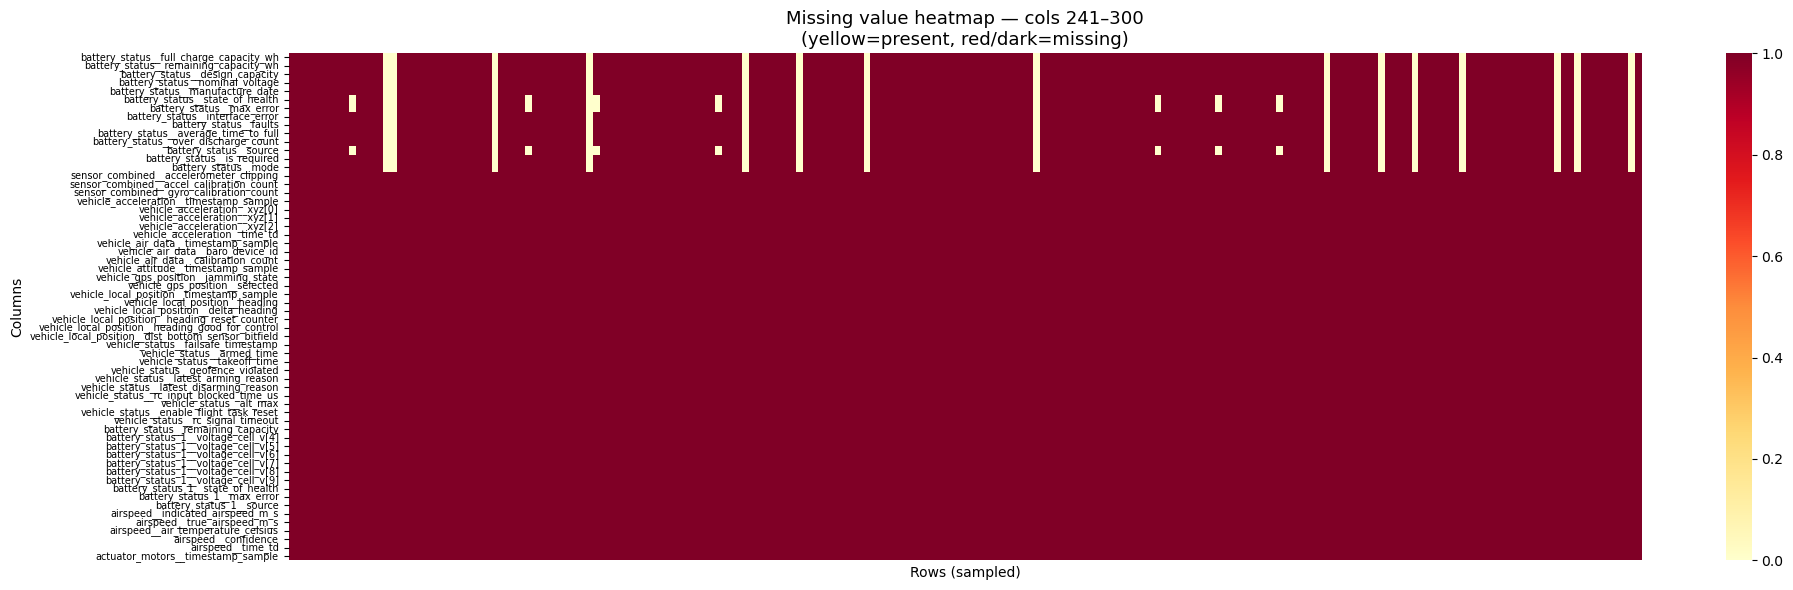

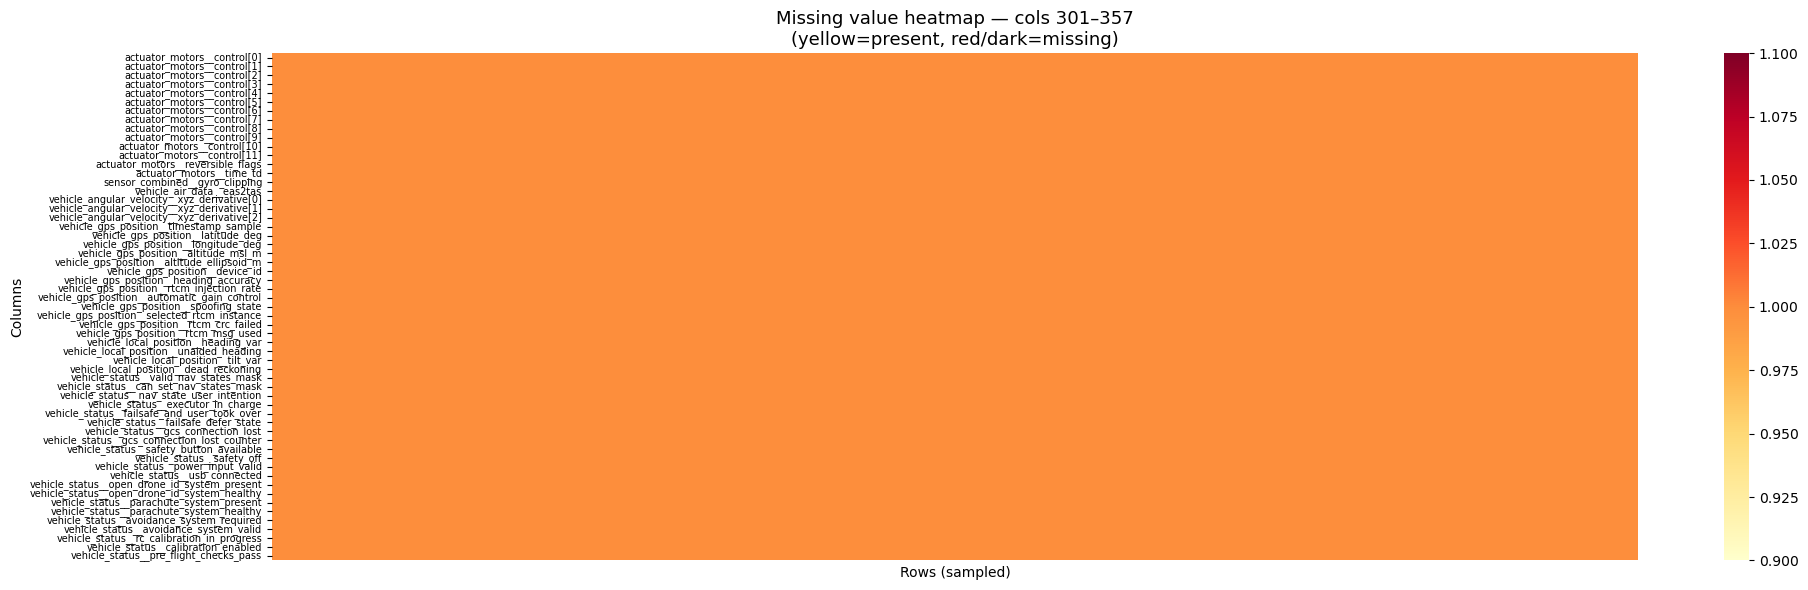

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Use a sample of rows for speed (1M rows is slow to compute isnull on for plotting)
SAMPLE_N = 50000
sample_df = df.sample(n=SAMPLE_N, random_state=42)

# Compute % missing per column
miss_pct = sample_df.isnull().mean() * 100

# Split into bands for readability (378 cols won't fit in one plot)
def plot_missing_heatmap(df_subset, title_suffix):
    fig, ax = plt.subplots(figsize=(20, 6))
    # Create a boolean matrix: 1 = missing
    bool_matrix = df_subset.isnull().astype(int)
    # Downsample rows further for the visual (heatmap pixel rows)
    step = max(1, len(bool_matrix) // 200)
    sns.heatmap(
        bool_matrix.iloc[::step].T,
        ax=ax,
        cbar=True,
        cmap="YlOrRd",
        yticklabels=True,
        xticklabels=False,
        linewidths=0
    )
    ax.set_title(f"Missing value heatmap — {title_suffix}\n(yellow=present, red/dark=missing)", fontsize=13)
    ax.set_xlabel("Rows (sampled)", fontsize=10)
    ax.set_ylabel("Columns", fontsize=10)
    ax.tick_params(axis='y', labelsize=7)
    plt.tight_layout()
    plt.savefig(EDA_DIR / f"missing_heatmap_{title_suffix.replace(' ','_')}.png", dpi=150)
    plt.show()

# Filter to columns with any missingness (skip fully-present cols)
cols_with_missing = miss_pct[miss_pct > 0].index.tolist()
print(f"Columns with any missing values: {len(cols_with_missing)} / {len(df.columns)}")

# Plot in chunks of 60 cols so labels are readable
CHUNK = 60
for i in range(0, len(cols_with_missing), CHUNK):
    chunk_cols = cols_with_missing[i:i+CHUNK]
    plot_missing_heatmap(sample_df[chunk_cols], f"cols {i+1}–{min(i+CHUNK, len(cols_with_missing))}")

## 6. Remove unusable columns before feature testing

In [9]:
MISSING_THRESHOLD = 80

# Numeric columns only for modelling
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()

candidate_features = []

for col in numeric_cols:
    if col in cols_to_exclude:
        continue
    
    if col == target_col:
        continue
    
    missing_percent = train_df[col].isna().mean() * 100
    
    if missing_percent >= MISSING_THRESHOLD:
        continue
    
    if train_df[col].nunique(dropna=True) <= 1:
        continue
    
    candidate_features.append(col)

print("Candidate features after leakage, missingness, and constant-column filtering:")
print(len(candidate_features))

print(candidate_features)

Candidate features after leakage, missingness, and constant-column filtering:
18
['battery_status__voltage_v', 'battery_status__voltage_filtered_v', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__cell_count', 'battery_status__warning', 'time_s', 'power_w', 'energy_increment_wh', 'cumulative_energy_wh', 'battery_status__system_source', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]']


## 7. Correlation analysis with target

In [10]:
# Correlation is calculated using training data only

correlation_rows = []

for col in candidate_features:
    temp = train_df[[col, target_col]].dropna()
    
    if len(temp) < 100:
        continue
    
    pearson_corr = temp[col].corr(temp[target_col], method="pearson")
    spearman_corr = temp[col].corr(temp[target_col], method="spearman")
    
    correlation_rows.append({
        "column": col,
        "pearson_corr": pearson_corr,
        "abs_pearson_corr": abs(pearson_corr) if pd.notna(pearson_corr) else np.nan,
        "spearman_corr": spearman_corr,
        "abs_spearman_corr": abs(spearman_corr) if pd.notna(spearman_corr) else np.nan
    })

correlation_report = pd.DataFrame(correlation_rows)

correlation_report = correlation_report.sort_values(
    "abs_pearson_corr",
    ascending=False
).reset_index(drop=True)

display(correlation_report.head(40))

,column,pearson_corr,abs_pearson_corr,spearman_corr,abs_spearman_corr
0,power_w,0.958426,0.958426,0.921192,0.921192
1,energy_increment_wh,0.958426,0.958426,0.921192,0.921192
2,battery_status__current_filtered_a,0.752196,0.752196,0.801068,0.801068
3,battery_status__current_a,0.738893,0.738893,0.807097,0.807097
4,cumulative_energy_wh,0.716135,0.716135,0.794495,0.794495
5,battery_status__discharged_mah,0.674061,0.674061,0.666883,0.666883
6,battery_status__cell_count,0.658864,0.658864,0.344438,0.344438
7,battery_status__voltage_filtered_v,0.612879,0.612879,0.239004,0.239004
8,battery_status__voltage_v,0.609209,0.609209,0.250300,0.250300
9,time_s,0.387584,0.387584,0.292344,0.292344


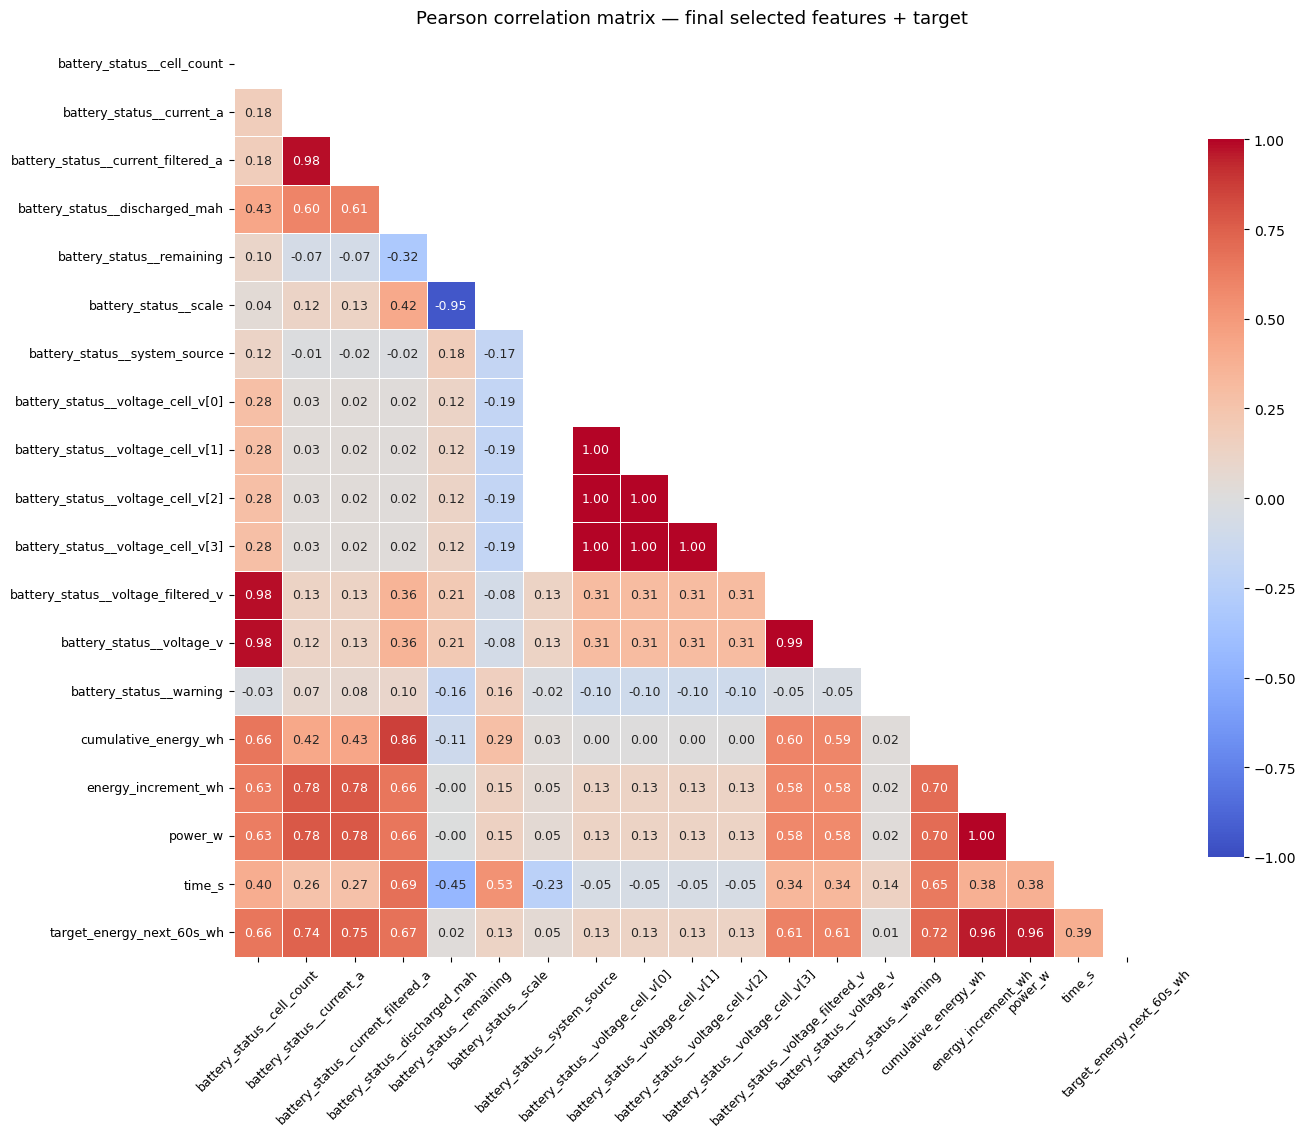


Top correlations with target:
power_w                               0.958426
energy_increment_wh                   0.958426
battery_status__current_filtered_a    0.752196
battery_status__current_a             0.738893
cumulative_energy_wh                  0.716135
battery_status__discharged_mah        0.674061
battery_status__cell_count            0.658864
battery_status__voltage_filtered_v    0.612879
battery_status__voltage_v             0.609209
time_s                                0.387584
battery_status__scale                 0.127739
battery_status__voltage_cell_v[3]     0.127532
battery_status__voltage_cell_v[1]     0.127532
battery_status__voltage_cell_v[0]     0.127532
battery_status__voltage_cell_v[2]     0.127532
battery_status__system_source         0.050642
battery_status__remaining             0.017126
battery_status__warning               0.014004
Name: target_energy_next_60s_wh, dtype: float64


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Use final_feature_cols + target (already selected in your notebook)
corr_cols = final_feature_cols + [target_col]
corr_df = train_df[corr_cols].copy()

# Compute Pearson correlation
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(14, 12))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # upper triangle mask

sns.heatmap(
    corr_matrix,
    ax=ax,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.7},
    annot_kws={"size": 9}
)

ax.set_title("Pearson correlation matrix — final selected features + target", fontsize=13, pad=12)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)

plt.tight_layout()
plt.savefig(EDA_DIR / "correlation_matrix_final_features.png", dpi=150)
plt.show()

# Also print top correlations with target
print("\nTop correlations with target:")
print(corr_matrix[target_col].drop(target_col).abs().sort_values(ascending=False).head(21))

Mutual information analysis

In [11]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# To make this faster, sample training data
MI_SAMPLE_SIZE = 100_000

mi_train_sample = train_df[candidate_features + [target_col]].dropna(subset=[target_col]).copy()

if len(mi_train_sample) > MI_SAMPLE_SIZE:
    mi_train_sample = mi_train_sample.sample(
        n=MI_SAMPLE_SIZE,
        random_state=42
    )

X_mi = mi_train_sample[candidate_features]
y_mi = mi_train_sample[target_col]

# Impute missing values using median
imputer_for_mi = SimpleImputer(strategy="median")
X_mi_imputed = imputer_for_mi.fit_transform(X_mi)

mi_scores = mutual_info_regression(
    X_mi_imputed,
    y_mi,
    random_state=42
)

mi_report = pd.DataFrame({
    "column": candidate_features,
    "mutual_information_score": mi_scores
}).sort_values(
    "mutual_information_score",
    ascending=False
).reset_index(drop=True)

display(mi_report.head(40))

,column,mutual_information_score
0,cumulative_energy_wh,2.566159
1,battery_status__discharged_mah,2.544335
2,battery_status__current_filtered_a,2.243245
3,battery_status__voltage_filtered_v,2.073943
4,energy_increment_wh,1.778297
5,power_w,1.778284
6,battery_status__voltage_v,1.771139
7,battery_status__current_a,1.666499
8,battery_status__remaining,1.321248
9,time_s,1.254320


## 8. Mutual information analysis

In [12]:
feature_report = missing_report[[
    "column",
    "missing_percent_train",
    "data_type",
    "unique_values_train"
]].copy()

feature_report = feature_report.merge(
    correlation_report,
    on="column",
    how="left"
)

feature_report = feature_report.merge(
    mi_report,
    on="column",
    how="left"
)

feature_report["is_candidate_feature"] = feature_report["column"].isin(candidate_features)
feature_report["is_core_feature"] = feature_report["column"].isin(allowed_core_features)
feature_report["cols_to_exclude"] = feature_report["column"].isin(cols_to_exclude )

feature_report["selection_reason"] = "Not selected"

feature_report.loc[
    feature_report["cols_to_exclude"],
    "selection_reason"
] = "Removed: identifier, label, or future/target leakage column"

feature_report.loc[
    feature_report["missing_percent_train"] >= 80,
    "selection_reason"
] = "Removed: high missing values"

feature_report.loc[
    feature_report["unique_values_train"] <= 1,
    "selection_reason"
] = "Removed: constant or near-constant column"

feature_report.loc[
    feature_report["is_candidate_feature"],
    "selection_reason"
] = "Candidate: passed missingness, leakage, and variance checks"

feature_report.loc[
    feature_report["is_core_feature"] & feature_report["is_candidate_feature"],
    "selection_reason"
] = "Selected: domain-relevant battery/energy feature and passed quality checks"

display(
    feature_report.sort_values(
        ["is_candidate_feature", "mutual_information_score", "abs_pearson_corr"],
        ascending=[False, False, False]
    ).head(80)
)

,column,missing_percent_train,data_type,unique_values_train,pearson_corr,abs_pearson_corr,spearman_corr,abs_spearman_corr,mutual_information_score,is_candidate_feature,is_core_feature,cols_to_exclude,selection_reason
373,cumulative_energy_wh,0.0,float64,523534,0.716135,0.716135,0.794495,0.794495,2.566159,True,True,False,Selected: domain-relevant battery/energy featu...
360,battery_status__discharged_mah,0.0,float64,132624,0.674061,0.674061,0.666883,0.666883,2.544335,True,True,False,Selected: domain-relevant battery/energy featu...
357,battery_status__current_filtered_a,0.0,float64,135659,0.752196,0.752196,0.801068,0.801068,2.243245,True,True,False,Selected: domain-relevant battery/energy featu...
363,battery_status__voltage_filtered_v,0.0,float64,136048,0.612879,0.612879,0.239004,0.239004,2.073943,True,True,False,Selected: domain-relevant battery/energy featu...
372,energy_increment_wh,0.0,float64,106810,0.958426,0.958426,0.921192,0.921192,1.778297,True,True,False,Selected: domain-relevant battery/energy featu...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,vehicle_status__mission_failure,100.0,float64,0,NaN,NaN,NaN,NaN,NaN,False,False,False,Removed: constant or near-constant column
58,vehicle_status__time_td,100.0,float64,0,NaN,NaN,NaN,NaN,NaN,False,False,False,Removed: constant or near-constant column
59,vehicle_status__gcs_connection_lost_counter,100.0,float64,0,NaN,NaN,NaN,NaN,NaN,False,False,False,Removed: constant or near-constant column
60,vehicle_status__gcs_connection_lost,100.0,float64,0,NaN,NaN,NaN,NaN,NaN,False,False,False,Removed: constant or near-constant column


## 9. Combine missingness, correlation, and mutual information into one decision report

In [13]:
# Top features based on correlation
top_corr_features = correlation_report.head(30)["column"].tolist()

# Top features based on mutual information
top_mi_features = mi_report.head(30)["column"].tolist()

# Core features that are available and passed candidate filtering
valid_core_features = [
    col for col in allowed_core_features
    if col in candidate_features
]

# Combine all selected features
final_feature_cols = sorted(
    list(set(valid_core_features + top_corr_features + top_mi_features))
)

print("Final selected feature count:", len(final_feature_cols))

print("\nFinal selected features:")
for col in final_feature_cols:
    print(col)

Final selected feature count: 18

Final selected features:
battery_status__cell_count
battery_status__current_a
battery_status__current_filtered_a
battery_status__discharged_mah
battery_status__remaining
battery_status__scale
battery_status__system_source
battery_status__voltage_cell_v[0]
battery_status__voltage_cell_v[1]
battery_status__voltage_cell_v[2]
battery_status__voltage_cell_v[3]
battery_status__voltage_filtered_v
battery_status__voltage_v
battery_status__warning
cumulative_energy_wh
energy_increment_wh
power_w
time_s


## 10. Select final model features based on evidence

In [ ]:
## 11. Final model-ready datasets

Train model shape: (631004, 21)
Validation model shape: (185751, 21)
Test model shape: (203236, 21)


,log_id,dataset_label,battery_status__cell_count,battery_status__current_a,battery_status__current_filtered_a,battery_status__discharged_mah,battery_status__remaining,battery_status__scale,battery_status__system_source,battery_status__voltage_cell_v[0],...,battery_status__voltage_cell_v[2],battery_status__voltage_cell_v[3],battery_status__voltage_filtered_v,battery_status__voltage_v,battery_status__warning,cumulative_energy_wh,energy_increment_wh,power_w,time_s,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.0,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.1,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.2,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.3,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.46793,0.088367,0.016040,0.784237,1.040576,1.0,NaN,...,NaN,NaN,11.754977,11.730804,0.0,0.000152,0.000152,5.489191,0.4,0.001109


## 11. Save reports and final datasets

In [15]:
from pathlib import Path

OUTPUT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

SPLIT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/splits")
SPLIT_DIR.mkdir(exist_ok=True)

# Save feature selection evidence
feature_report.to_excel(
    OUTPUT_DIR / "feature_selection_evidence_report.xlsx",
    index=False
)

correlation_report.to_csv(
    OUTPUT_DIR / "correlation_with_target_report.csv",
    index=False
)

mi_report.to_csv(
    OUTPUT_DIR / "mutual_information_report.csv",
    index=False
)

# Save model-ready datasets
train_model_df.to_csv(SPLIT_DIR / "train_model_ready_selected_features.csv", index=False)
val_model_df.to_csv(SPLIT_DIR / "val_model_ready_selected_features.csv", index=False)
test_model_df.to_csv(SPLIT_DIR / "test_model_ready_selected_features.csv", index=False)

print("Saved feature selection reports and final model-ready datasets.")
print("Output folder:", OUTPUT_DIR)
print("Split folder:", SPLIT_DIR)

Saved feature selection reports and final model-ready datasets.
Output folder: /Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/eda_outputs
Split folder: /Users/arjun/Documents/UAV thesis/uav_px4_dataset_project/splits


normal: n=719,371  median=0.933  p99=53.076  max=66.088
abnormal: n=300,620  median=2.776  p99=24.630  max=27.502


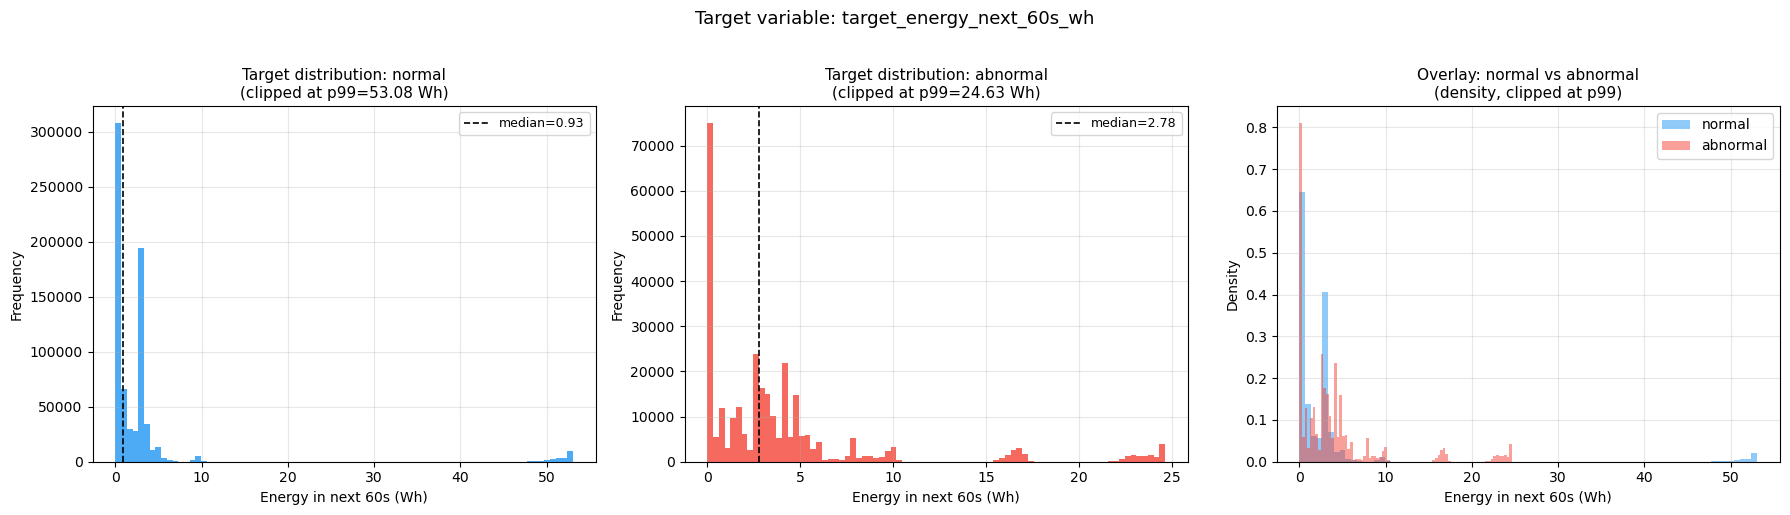

In [19]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

labels_and_axes = [
    ("normal", axes[0]),
    ("abnormal", axes[1]),
    (None, axes[2])   # combined
]

colors = {"normal": "#2196F3", "abnormal": "#F44336"}

for label, ax in labels_and_axes[:2]:
    subset = df[df["dataset_label"] == label][target_col].dropna()
    # Clip extreme outliers for visual clarity (log the clip threshold)
    p99 = np.percentile(subset, 99)
    clipped = subset.clip(upper=p99)
    print(f"{label}: n={len(subset):,}  median={subset.median():.3f}  p99={p99:.3f}  max={subset.max():.3f}")
    ax.hist(clipped, bins=80, color=colors[label], alpha=0.8, edgecolor="none")
    ax.axvline(subset.median(), color="black", linestyle="--", linewidth=1.2, label=f"median={subset.median():.2f}")
    ax.set_title(f"Target distribution: {label}\n(clipped at p99={p99:.2f} Wh)", fontsize=11)
    ax.set_xlabel("Energy in next 60s (Wh)")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

# Combined overlay
ax = axes[2]
for label in ["normal", "abnormal"]:
    subset = df[df["dataset_label"] == label][target_col].dropna()
    p99 = np.percentile(subset, 99)
    ax.hist(subset.clip(upper=p99), bins=80, alpha=0.5, label=label,
            color=colors[label], edgecolor="none", density=True)
ax.set_title("Overlay: normal vs abnormal\n(density, clipped at p99)", fontsize=11)
ax.set_xlabel("Energy in next 60s (Wh)")
ax.set_ylabel("Density")
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle("Target variable: target_energy_next_60s_wh", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(EDA_DIR / "target_distribution_all.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Identify which flights contain high-energy rows

In [ ]:
## 14. Plot the suspect flights' full time series

Rows with target > 20 Wh in NORMAL flights: 22,062
That is 3.067% of normal rows

Flights affected: 1 / 129 total normal flights

                              log_id  n_high_rows  max_target  mean_target  p95_target
e68d22d7-7b96-4767-a074-edfca1c7f78c        22062   66.087665    52.342273   55.178231


## 13. Statistical outlier test (IQR + Z-score)

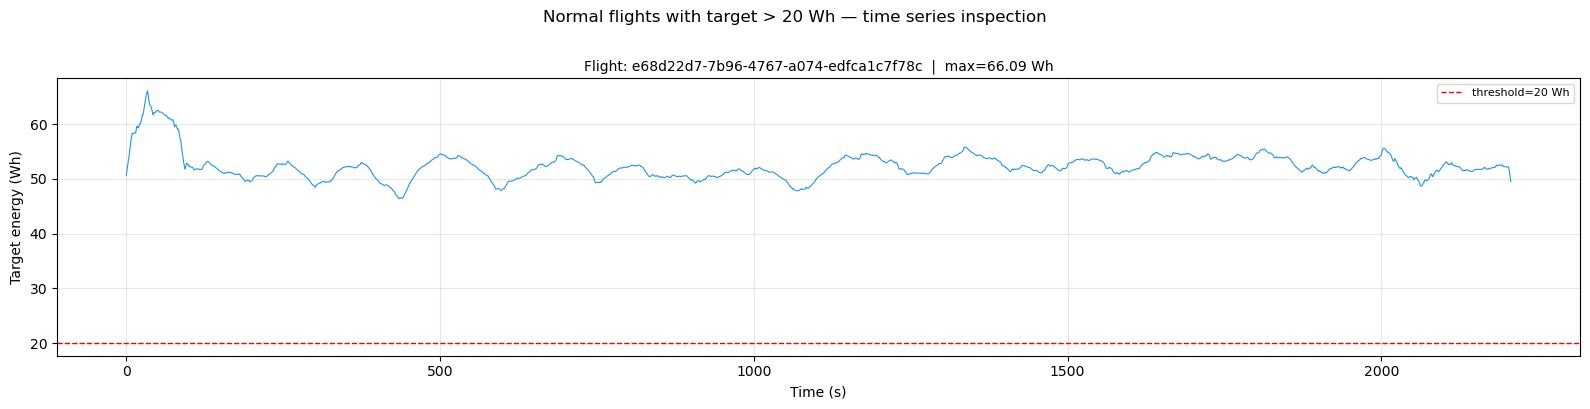

In [ ]:
## 16. Cross-check with power_w

Statistical outlier test (IQR + Z-score)

=== IQR Method ===
  Q1=0.2779  Q3=3.0706  IQR=2.7926
  Outlier threshold (Q3 + 3×IQR): 11.4485 Wh
  Rows above threshold: 22,062 (3.067%)

=== Z-score Method (|z| > 3) ===
  Rows flagged: 22,062 (3.067%)
  Minimum flagged value: 46.4028 Wh

=== Percentile breakdown ===
  p90: 3.6068 Wh
  p95: 5.3111 Wh
  p99: 53.0762 Wh
  p99.5: 54.0081 Wh
  p99.9: 58.3473 Wh
  p100: 66.0877 Wh


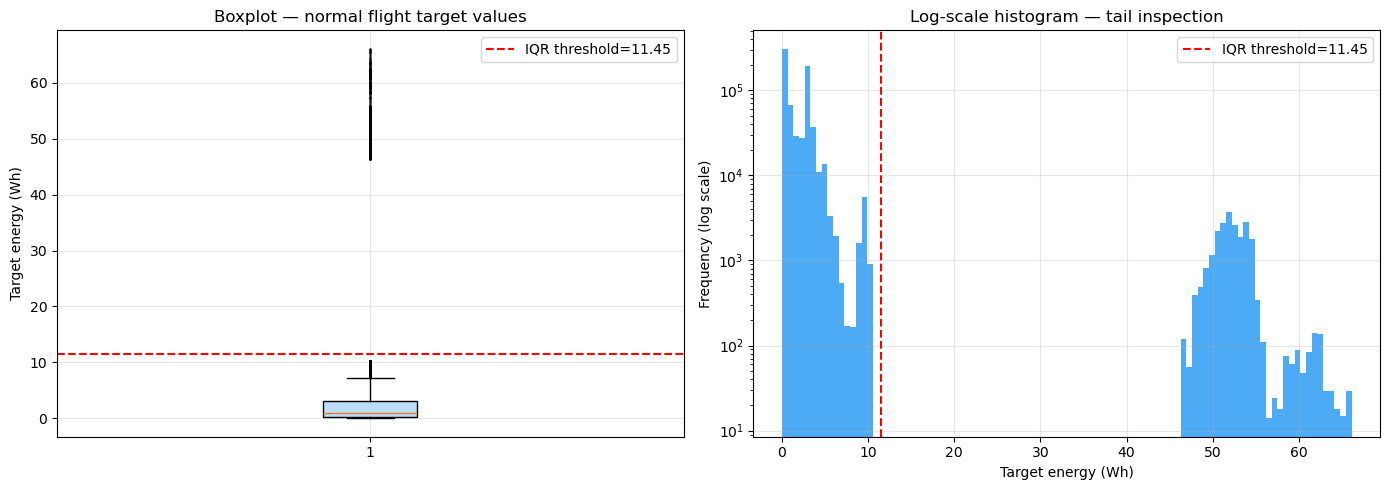

In [22]:
from scipy import stats

target_vals = normal_df[target_col].dropna()

# IQR method
Q1 = target_vals.quantile(0.25)
Q3 = target_vals.quantile(0.75)
IQR = Q3 - Q1
iqr_upper = Q3 + 3 * IQR   # using 3x IQR (stricter than 1.5x for large datasets)

# Z-score method
z_scores = np.abs(stats.zscore(target_vals))
z_upper = target_vals[z_scores > 3].min() if (z_scores > 3).any() else None

print("=== IQR Method ===")
print(f"  Q1={Q1:.4f}  Q3={Q3:.4f}  IQR={IQR:.4f}")
print(f"  Outlier threshold (Q3 + 3×IQR): {iqr_upper:.4f} Wh")
print(f"  Rows above threshold: {(target_vals > iqr_upper).sum():,} ({100*(target_vals > iqr_upper).mean():.3f}%)")

print("\n=== Z-score Method (|z| > 3) ===")
print(f"  Rows flagged: {(z_scores > 3).sum():,} ({100*(z_scores > 3).mean():.3f}%)")
if z_upper:
    print(f"  Minimum flagged value: {z_upper:.4f} Wh")

print("\n=== Percentile breakdown ===")
for p in [90, 95, 99, 99.5, 99.9, 100]:
    print(f"  p{p}: {np.percentile(target_vals, p):.4f} Wh")

# Plot boxplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.boxplot(target_vals, vert=True, patch_artist=True,
            boxprops=dict(facecolor="#BBDEFB"), flierprops=dict(marker='.', markersize=1, alpha=0.3))
ax1.axhline(iqr_upper, color='red', linestyle='--', label=f'IQR threshold={iqr_upper:.2f}')
ax1.set_title("Boxplot — normal flight target values")
ax1.set_ylabel("Target energy (Wh)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Log-scale histogram to see tail clearly
ax2.hist(target_vals, bins=100, color="#2196F3", alpha=0.8, edgecolor="none", log=True)
ax2.axvline(iqr_upper, color='red', linestyle='--', label=f'IQR threshold={iqr_upper:.2f}')
ax2.set_title("Log-scale histogram — tail inspection")
ax2.set_xlabel("Target energy (Wh)")
ax2.set_ylabel("Frequency (log scale)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_statistical_test_normal.png", dpi=150)
plt.show()

Cross-check with power_w 

Top 20 high-target rows with their power_w values:
                              log_id  time_s   power_w  energy_increment_wh  cumulative_energy_wh  target_energy_next_60s_wh
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.6 3593.2422             0.099812             23.708082                  66.087665
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.7 3593.2422             0.099812             23.807894                  66.071539
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.8 3387.1223             0.094087             23.901981                  66.061138
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.5 3226.6917             0.089630             23.608269                  66.060095
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.9 3387.1223             0.094087             23.996067                  66.026597
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.4 3226.6917             0.089630             23.518639                  66.022343
e68d22d7-7b96-4767-a074-edfca1c7f78c    34.0 3477.0989             0.09658

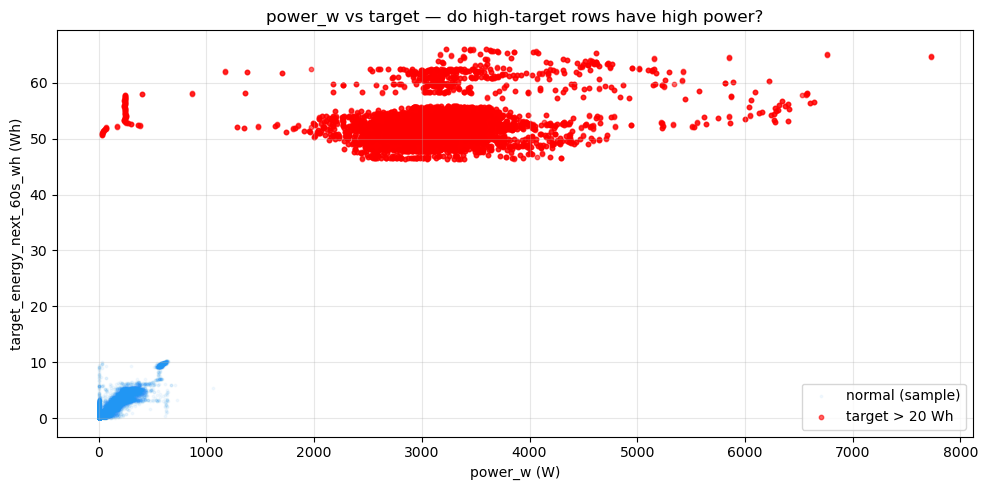

In [23]:
high_rows = normal_df[normal_df[target_col] > THRESHOLD][
    ["log_id", "time_s", "power_w", "energy_increment_wh", "cumulative_energy_wh", target_col]
].sort_values(target_col, ascending=False)

print("Top 20 high-target rows with their power_w values:")
print(high_rows.head(20).to_string(index=False))

print(f"\nAmong these rows:")
print(f"  mean power_w    : {high_rows['power_w'].mean():.2f} W")
print(f"  max  power_w    : {high_rows['power_w'].max():.2f} W")
print(f"  Normal flight overall mean power_w: {normal_df['power_w'].mean():.2f} W")
print(f"  Normal flight p99 power_w         : {normal_df['power_w'].quantile(0.99):.2f} W")

# Scatter: power_w vs target
fig, ax = plt.subplots(figsize=(10, 5))
sample = normal_df.sample(min(50000, len(normal_df)), random_state=42)
ax.scatter(sample["power_w"], sample[target_col], alpha=0.05, s=3, color="#2196F3", label="normal (sample)")
ax.scatter(high_rows["power_w"], high_rows[target_col], alpha=0.6, s=10, color="red", label=f"target > {THRESHOLD} Wh")
ax.set_xlabel("power_w (W)")
ax.set_ylabel("target_energy_next_60s_wh (Wh)")
ax.set_title("power_w vs target — do high-target rows have high power?")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "power_vs_target_outlier_check.png", dpi=150)
plt.show()

reverification before removing this flight

=== Removal Justification (save this for dissertation) ===
Flight ID     : e68d22d7-7b96-4767-a074-edfca1c7f78c
Label         : normal (MISLABELLED)
Rows          : 22,062 (3.067% of normal data)
Mean power_w  : 3133 W  (fleet mean: 193 W — 16× higher)
Mean target   : 52.34 Wh  (fleet median: 0.93 Wh)
Reason        : Bimodal distribution gap + single-flight origin +
                sustained anomalous power for entire flight duration.
Decision      : Remove entire flight from dataset (not just rows).

Before removal : 1,019,991 rows, 172 flights
After removal  : 997,929 rows, 171 flights

Normal target after removal:
  max : 10.3092 Wh
  p99 : 9.2226 Wh
  mean: 1.6888 Wh


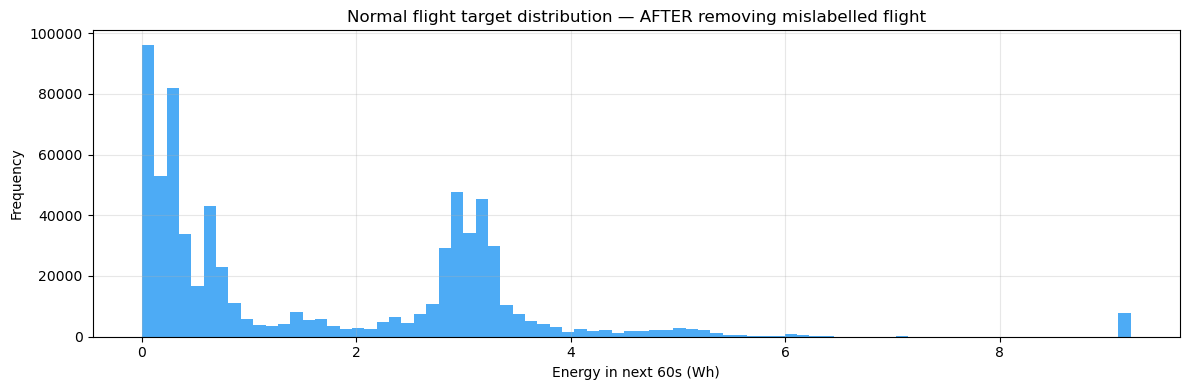


df updated. Re-run your train/val/test split from this point.


In [24]:
# Document the evidence first
suspect_id = "e68d22d7-7b96-4767-a074-edfca1c7f78c"

print("=== Removal Justification (save this for dissertation) ===")
print(f"Flight ID     : {suspect_id}")
print(f"Label         : normal (MISLABELLED)")
print(f"Rows          : 22,062 (3.067% of normal data)")
print(f"Mean power_w  : 3133 W  (fleet mean: 193 W — 16× higher)")
print(f"Mean target   : 52.34 Wh  (fleet median: 0.93 Wh)")
print(f"Reason        : Bimodal distribution gap + single-flight origin +")
print(f"                sustained anomalous power for entire flight duration.")
print(f"Decision      : Remove entire flight from dataset (not just rows).")

# Remove from main df
df_clean = df[df["log_id"] != suspect_id].copy()

print(f"\nBefore removal : {len(df):,} rows, {df['log_id'].nunique()} flights")
print(f"After removal  : {len(df_clean):,} rows, {df_clean['log_id'].nunique()} flights")

# Verify the normal distribution looks clean now
normal_clean = df_clean[df_clean["dataset_label"] == "normal"][target_col]
print(f"\nNormal target after removal:")
print(f"  max : {normal_clean.max():.4f} Wh")
print(f"  p99 : {normal_clean.quantile(0.99):.4f} Wh")
print(f"  mean: {normal_clean.mean():.4f} Wh")

# Quick visual confirm
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(normal_clean.clip(upper=normal_clean.quantile(0.99)), 
        bins=80, color="#2196F3", alpha=0.8, edgecolor="none")
ax.set_title("Normal flight target distribution — AFTER removing mislabelled flight")
ax.set_xlabel("Energy in next 60s (Wh)")
ax.set_ylabel("Frequency")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "target_normal_cleaned.png", dpi=150)
plt.show()

# Replace df going forward
df = df_clean
print("\ndf updated. Re-run your train/val/test split from this point.")